# 📝 EDA Worksheet — Auto-MPG Dataset
**Student Name:** Ahmad & Qasim  |  **Date:** _______________

Complete every `# TODO` cell. Run the cells in order.  
Answer the written questions in the Markdown cells provided.

---
**Dataset:** Online Food Ordering Dataset

**Source:** Kaggle — srisyra02/online-food-ordering-dataset


## Task 1 — Import Libraries

In [1]:
# TODO: Import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

# Also set sns theme to 'whitegrid' and default figure size to (10,5)
sns.set_theme (style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10,5)
pd.set_option('display.max_columns', None)
print("Libraries loaded \u2713")

Libraries loaded ✓


## Task 2 — Load & Inspect Data

In [2]:
# TODO: Download the Online Food Ordering dataset from Kaggle

path = kagglehub.dataset_download("srisyra02/online-food-ordering-dataset")

print("Dataset path:", path)
print("Files:", os.listdir(path))

# TODO: Load the CSV file
df = pd.read_csv(os.path.join(path, "online food delivery dataset.csv"))
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'online-food-ordering-dataset' dataset.
Dataset path: /kaggle/input/online-food-ordering-dataset
Files: ['online food delivery dataset.csv']
Shape: (388, 14)


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


In [3]:
# TODO: Print df.info() to inspect dtypes and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 388 entries, 0 to 387
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         388 non-null    int64  
 1   Gender                      388 non-null    object 
 2   Marital Status              388 non-null    object 
 3   Occupation                  388 non-null    object 
 4   Monthly Income              388 non-null    object 
 5   Educational Qualifications  388 non-null    object 
 6   Family size                 388 non-null    int64  
 7   Customer Type               388 non-null    object 
 8   latitude                    388 non-null    float64
 9   longitude                   388 non-null    float64
 10  Pin code                    388 non-null    int64  
 11  Output                      388 non-null    object 
 12  Feedback                    388 non-null    object 
 13  Unnamed: 13                 388 non

In [4]:
# TODO: Print df.describe() to view summary statistics
df.describe(include='all').reset_index(drop=True)

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,388.000000,388,388,388,388,388,388.000000,388,388.000000,388.000000,388.000000,388,388,388
1,NaN,2,3,4,5,5,NaN,3,NaN,NaN,NaN,2,2,2
2,NaN,Male,Single,Student,No Income,Graduate,NaN,Regular,NaN,NaN,NaN,Yes,Positive,Yes
3,NaN,222,268,207,187,177,NaN,218,NaN,NaN,NaN,301,317,301
4,24.628866,NaN,NaN,NaN,NaN,NaN,3.280928,NaN,12.972058,77.600160,560040.113402,NaN,NaN,NaN
5,2.975593,NaN,NaN,NaN,NaN,NaN,1.351025,NaN,0.044489,0.051354,31.399609,NaN,NaN,NaN
6,18.000000,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,12.865200,77.484200,560001.000000,NaN,NaN,NaN
7,23.000000,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,12.936900,77.565275,560010.750000,NaN,NaN,NaN
8,24.000000,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,12.977000,77.592100,560033.500000,NaN,NaN,NaN
9,26.000000,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,12.997025,77.630900,560068.000000,NaN,NaN,NaN


## Task 3 — Pre-Processing

In [5]:
# TODO: Check and print missing values per column
print("Missing values per column:")
print(df.isnull().sum())

# Then drop all rows that contain NaN values (they are < 2% of data)
df = df.dropna().reset_index(drop=True)

print("\nShape after removing missing values:", df.shape)

Missing values per column:
Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
Customer Type                 0
latitude                      0
longitude                     0
Pin code                      0
Output                        0
Feedback                      0
Unnamed: 13                   0
dtype: int64

Shape after removing missing values: (388, 14)


In [6]:
# TODO: Check for and remove duplicate rows
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate rows: 103
Shape after removing duplicates: (285, 14)


In [7]:
# TODO:
# 1. Create two cat & num cols lists
# 2. Convert suitable columns to category dtype & .strip & .lowercase text columns
# 3. Clean categorical values where appropriate

cat_cols = ['Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Output', 'Feedback']

for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.lower().astype('category')

In [8]:
# cat_cols — categorical column names

num_cols = ['Age', 'Family size']

for col in num_cols:
    if col in df.columns:
        df[col] = df[col].astype('int64')

print("Categorical columns:", cat_cols)
print("Numerical columns:", num_cols)
print()

df.info()

Categorical columns: ['Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Output', 'Feedback']
Numerical columns: ['Age', 'Family size']

<class 'pandas.core.frame.DataFrame'>
Index: 285 entries, 0 to 386
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   Age                         285 non-null    int64   
 1   Gender                      285 non-null    category
 2   Marital Status              285 non-null    category
 3   Occupation                  285 non-null    category
 4   Monthly Income              285 non-null    category
 5   Educational Qualifications  285 non-null    category
 6   Family size                 285 non-null    int64   
 7   Customer Type               285 non-null    object  
 8   latitude                    285 non-null    float64 
 9   longitude                   285 non-null    float64 
 10  Pin code              

## Task 4 — Feature Engineering

In [9]:
# TODO: Create 'age_group' column using pd.cut()

df['age_group'] = pd.cut(
    df['Age'],
    bins=[0, 25, 35, 50, np.inf],
    labels=['young', 'adult', 'middle-aged', 'senior']
)

print(df[['Age', 'age_group']].head())

   Age age_group
0   20     young
1   24     young
2   22     young
3   22     young
4   22     young


In [10]:
# TODO: Create 'family_size_level'

df['family_size_level'] = pd.cut(
    pd.to_numeric(df['Family size'], errors='coerce'),
    bins=[0, 2, 4, np.inf],
    labels=['small', 'medium', 'large']
)

print(df[['Family size', 'family_size_level']].head())

   Family size family_size_level
0            4            medium
1            3            medium
2            3            medium
3            6             large
4            4            medium


## Task 5 — Categorical EDA

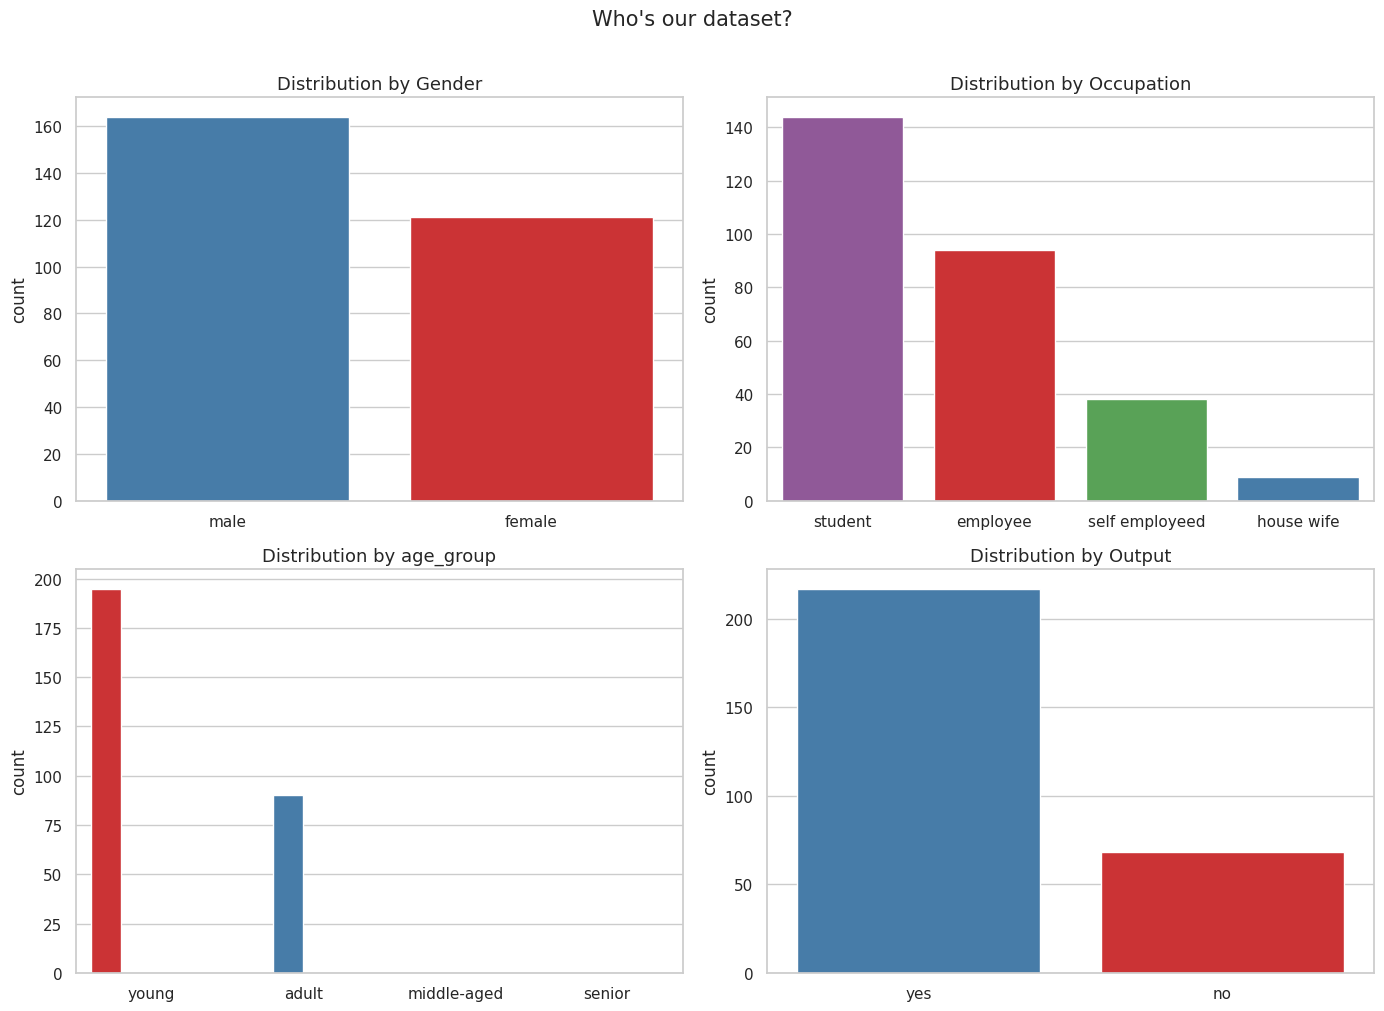

In [11]:
# TODO: Plot a countplot for each of: Gender, Occupation, age_group, Output
# Arrange them in a 2×2 grid of subplots

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, ['Gender', 'Occupation', 'age_group', 'Output']):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, palette='Set1', hue=col, legend=False)
    ax.set_title(f'Distribution by {col}', fontsize=13)
    ax.set_xlabel('')

plt.suptitle("Who's our dataset?", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

In [12]:
# TODO: Print the proportion (%) of the dominant class for Gender, Occupation, and Output

for col in ['Gender', 'Occupation', 'Output']:
    dominant_percentage = df[col].value_counts(normalize=True).iloc[0] * 100
    dominant_class = df[col].value_counts().index[0]

    print(
        f"{col}: {dominant_class} = "
        f"{dominant_percentage:.2f}%"
    )

Gender: male = 57.54%
Occupation: student = 50.53%
Output: yes = 76.14%


Output  no  yes
Gender         
female  31   90
male    37  127


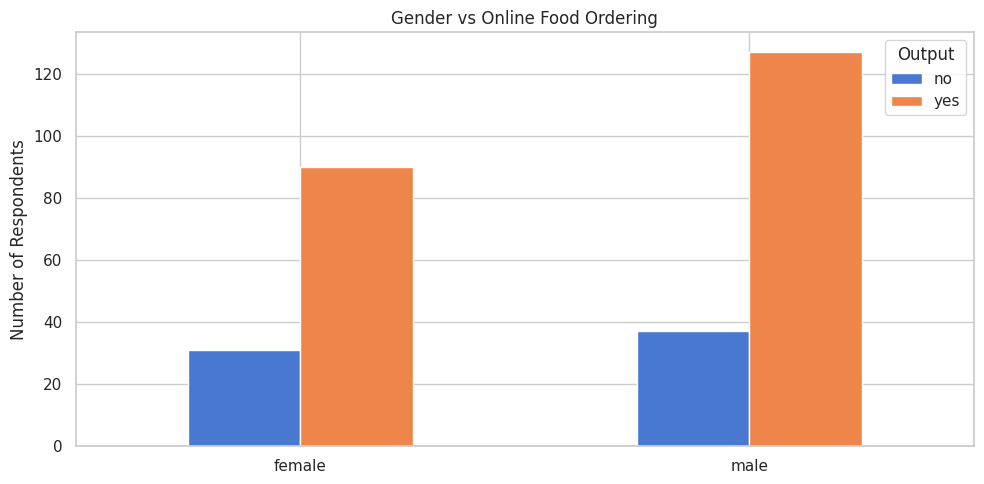

In [13]:
# TODO: Create a crosstab of Gender vs Output and visualise as a bar chart

gender_output = pd.crosstab(df['Gender'], df['Output'])
print(gender_output)

gender_output.plot(kind='bar', figsize=(10, 5))

plt.title('Gender vs Online Food Ordering')
plt.xlabel('')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Output')

plt.tight_layout()
plt.show()

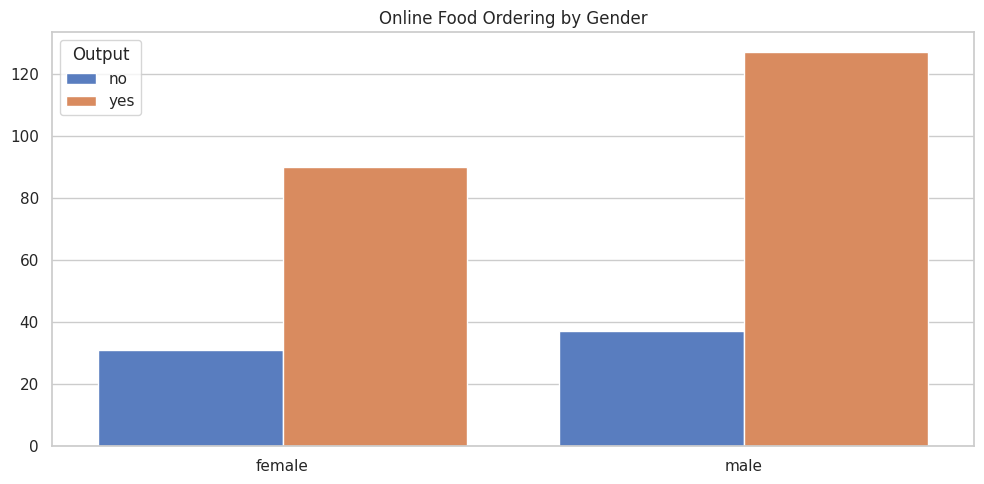

In [14]:
# TODO: Plot a countplot of Output grouped by Gender

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Gender', hue='Output')

plt.title('Online Food Ordering by Gender')
plt.xlabel('')
plt.ylabel('')

plt.tight_layout()
plt.show()

## Task 6 — Numerical EDA

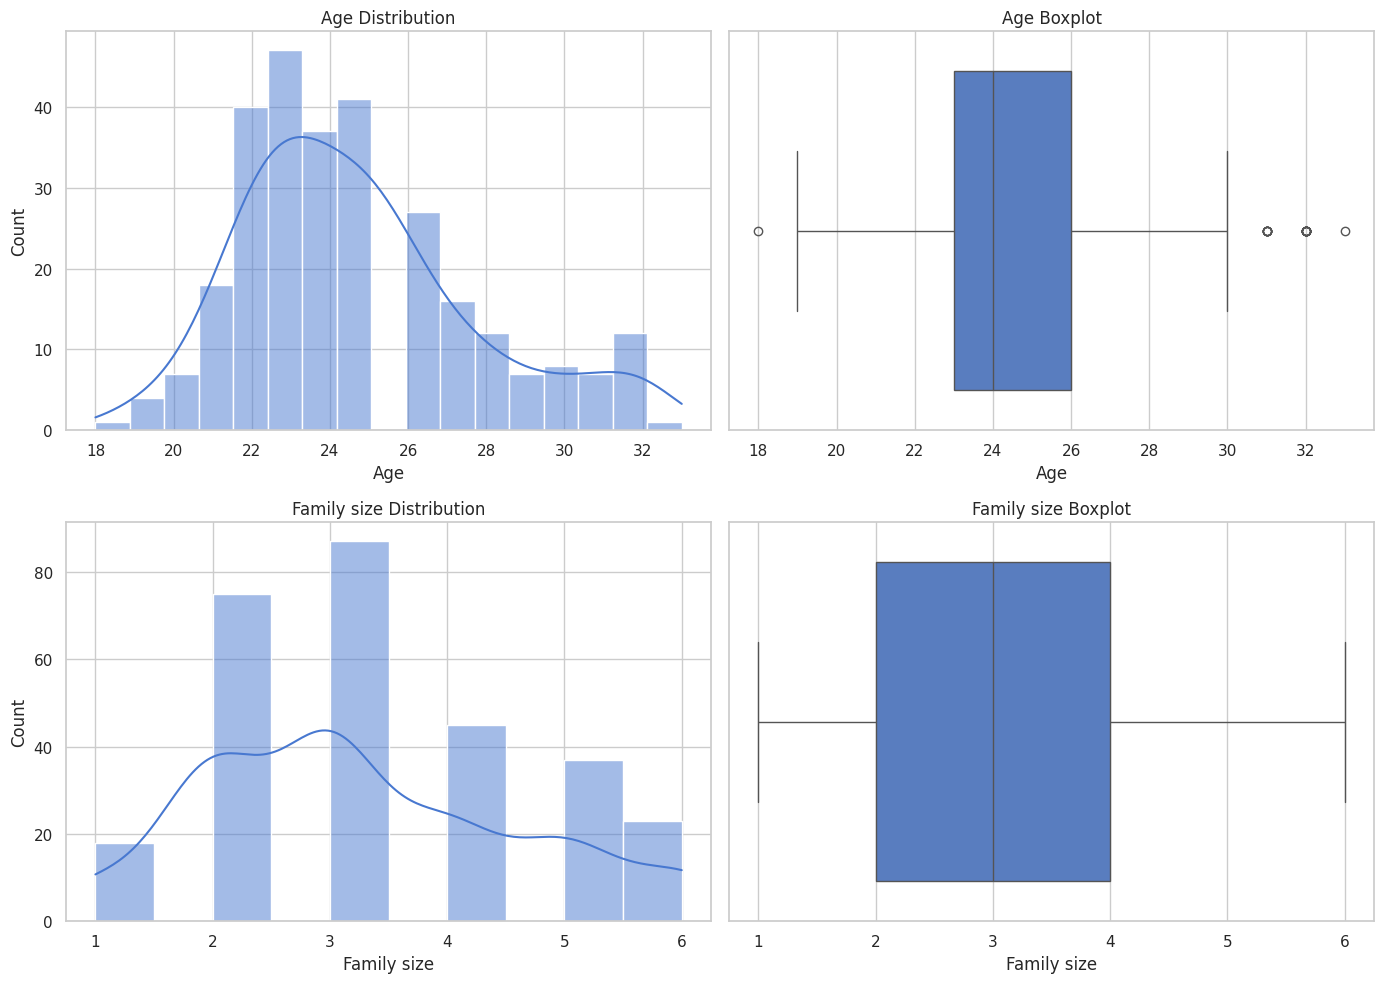

In [15]:
## Task 6 — Numerical EDA

# TODO: For each numerical column plot:
# (a) Histogram + KDE
# (b) Boxplot
# Arrange in a grid (n_cols rows × 2 columns)

fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 5 * len(num_cols)))

# Histogram+KDE_Plot
for i, col in enumerate(num_cols):

    sns.histplot(df[col], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'{col} Distribution')

    # Box_Plot
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f'{col} Boxplot')

plt.tight_layout()
plt.show()

In [16]:
# TODO: Write a function tukey_outliers(series) that returns the outlier values
# using the IQR (Tukey) rule: Q1 - 1.5*IQR  and  Q3 + 1.5*IQR

def tukey_outliers(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

    return series[(series < lower_bound) | (series > upper_bound)]

# Then print the outlier count for each numerical column
for col in num_cols:
  outliers = tukey_outliers(df[col])

  print(
      f"{col}: {len(outliers)} outliers"
  )

Age: 21 outliers
Family size: 0 outliers


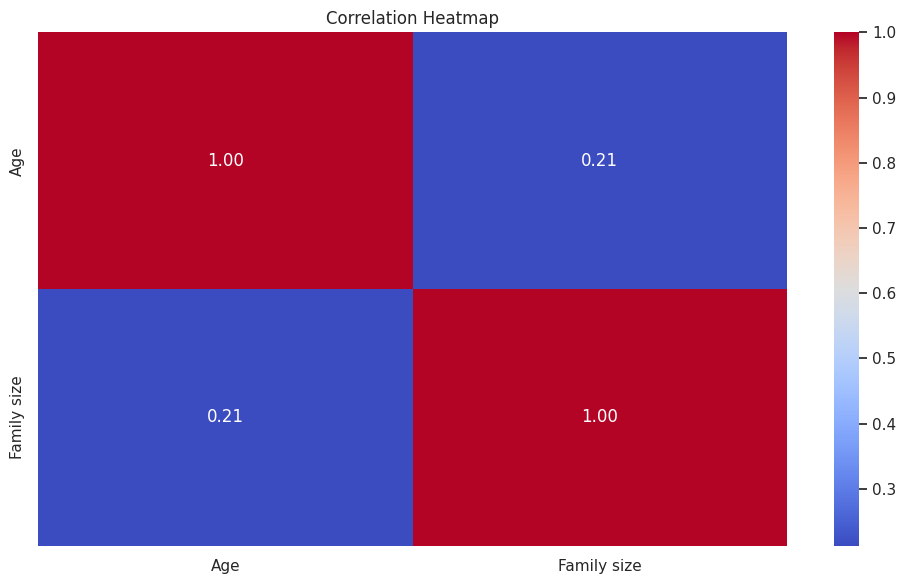

In [17]:
# TODO: Plot a correlation heatmap for all numerical columns (used annot=True)

plt.figure(figsize=(10, 6))

sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

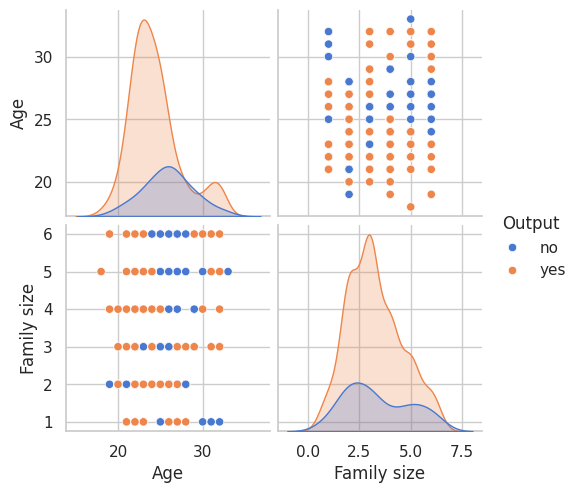

In [18]:
# TODO: Create a pairplot of numerical columns, coloured by Output

sns.pairplot(df, vars=num_cols, hue='Output')

plt.show()

## Task 7 — Numerical vs Categorical

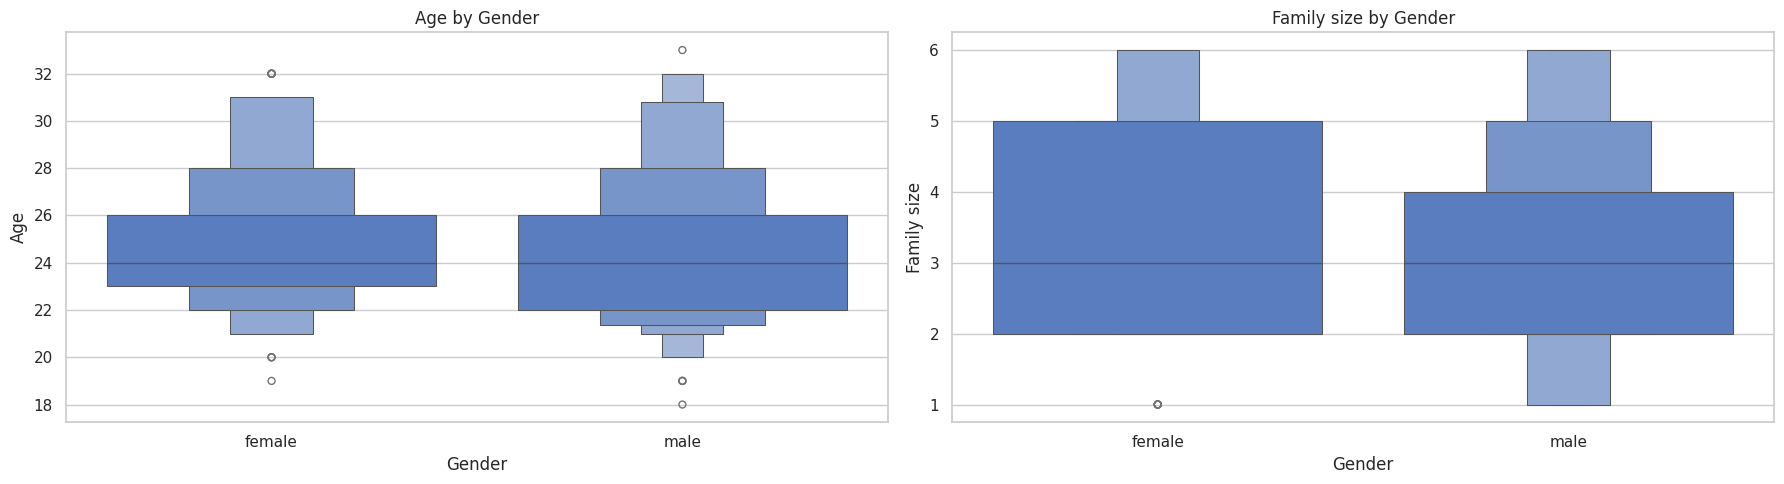

In [19]:
# TODO: Plot boxenplots of all numerical features grouped by Gender
# (1 row × n columns subplot grid)

fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 5))

for i, col in enumerate(num_cols):

    sns.boxenplot(data=df, x='Gender', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by Gender')

plt.tight_layout()
plt.show()

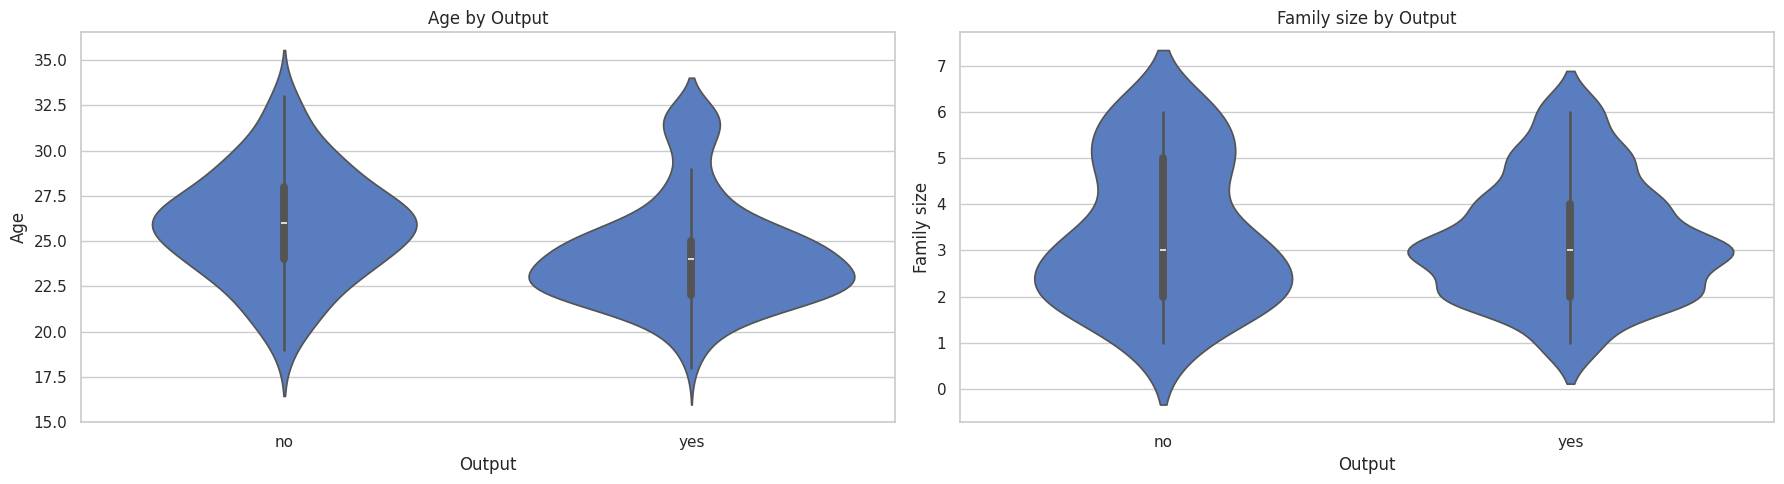

In [20]:
# TODO: Plot violinplots of all numerical features grouped by Output

fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 5))

for i, col in enumerate(num_cols):

    sns.violinplot(data=df, x='Output', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by Output')

plt.tight_layout()
plt.show()

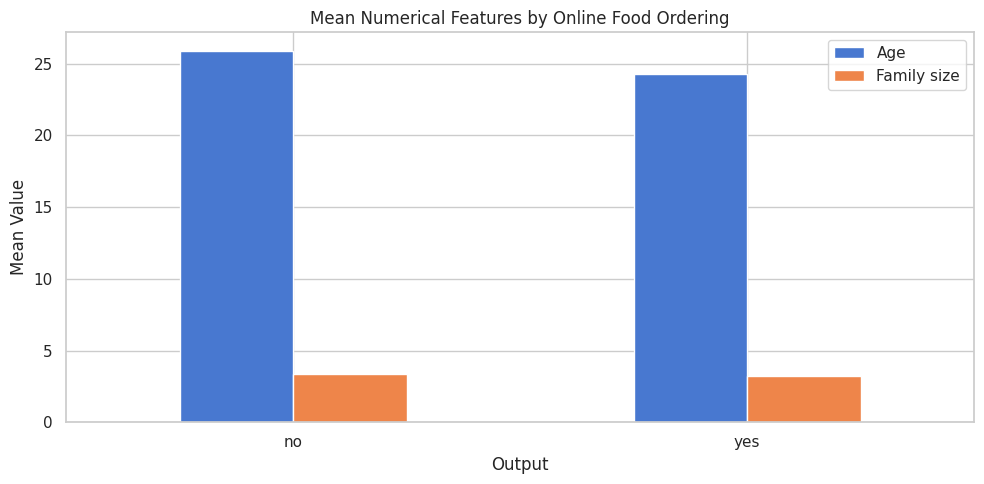

In [21]:
# TODO: Plot a bar chart showing mean Age and Family size by Output

mean_values = df.groupby('Output', observed=True)[num_cols].mean()

mean_values.plot(kind='bar', figsize=(10, 5))

plt.title('Mean Numerical Features by Online Food Ordering')
plt.xlabel('Output')
plt.ylabel('Mean Value')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## Task 8 — Summary Table
Fill in the table below based on your analysis.

| Feature | Relationship with Gender | Strength |
|---|---|---|
| Age | Age distribution differs between genders | Low |
| Family Size | Family size varies somewhat between genders | Low |
| Occupation | Occupation distribution differs between genders | Low |
| Monthly Income | Income categories vary somewhat between genders | Low |
| Educational Qualifications | Qualification distribution varies somewhat between genders | Low |
| Marital Status | Marital status distribution differs somewhat between genders | Low |
